In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

sns.set_style("whitegrid")

df = pd.read_csv("olist_analytical_dataset.csv")


In [3]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "review_creation_date",
    "review_answer_timestamp"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

## Feature Engineering: Delivery Delay

Created a new feature delivery_delay_days by subtracting the estimated delivery date from the actual delivery date.
delivery_delay_days = order_delivered_customer_date − order_estimated_delivery_date
Interpretation:
- Negative values → Order delivered before estimated date
- Positive values → Order delivered late
- Zero → Delivered on time

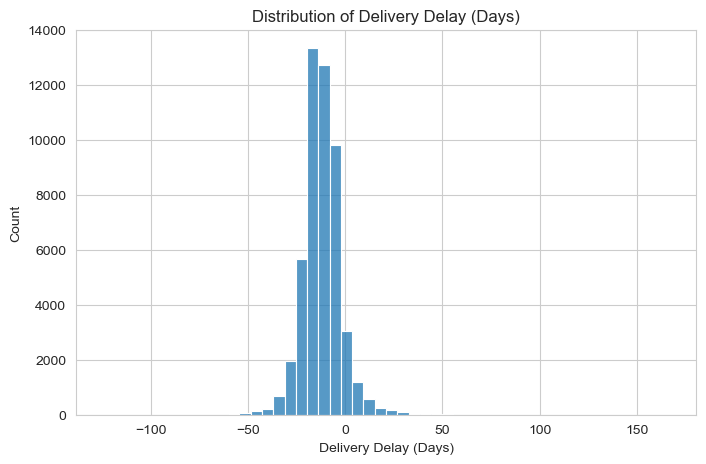

In [5]:
df["delivery_delay_days"] = (
    df["order_delivered_customer_date"] -
    df["order_estimated_delivery_date"]
).dt.days
plt.figure(figsize=(8,5))
sns.histplot(df["delivery_delay_days"], bins=50)
plt.title("Distribution of Delivery Delay (Days)")
plt.xlabel("Delivery Delay (Days)")
plt.savefig("Delivery_delay_histogram")
plt.show()

## Distribution of Delivery Delay

The histogram shows the distribution of delivery delays in days.
Observations:
- Most values are negative, indicating early deliveries.
- The distribution appears left-skewed.
- There are some extreme values (outliers) indicating unusually delayed deliveries.

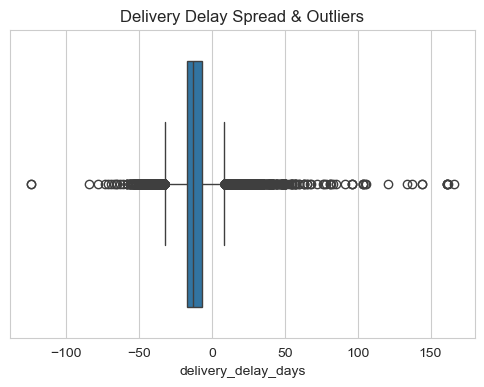

In [6]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["delivery_delay_days"])
plt.title("Delivery Delay Spread & Outliers")
plt.savefig("Delivery_delay_boxplot")
plt.show()

## Delivery Delay Spread & Outliers

The boxplot highlights the spread and presence of outliers.
Observations:
- The median delay is around -13 days.
- The interquartile range (IQR) is narrow, indicating most deliveries occur within a similar time frame.
- Several outliers exist, representing significantly late deliveries.

In [7]:
print("Mean delay:", df["delivery_delay_days"].mean())
print("Median delay:", df["delivery_delay_days"].median())

Mean delay: -12.029642371389711
Median delay: -13.0


Mean delivery delay: -12.03 days  
Median delivery delay: -13 days  

Interpretation:
- On average orders are delivered approximately 12–13 days before the estimated delivery date.
- Since the median is slightly lower than the mean, the distribution is slightly right-skewed due to late delivery outliers.
- The platform appears to deliver earlier than promised in most cases, but a long positive tail indicates extreme late deliveries affecting customer experience.

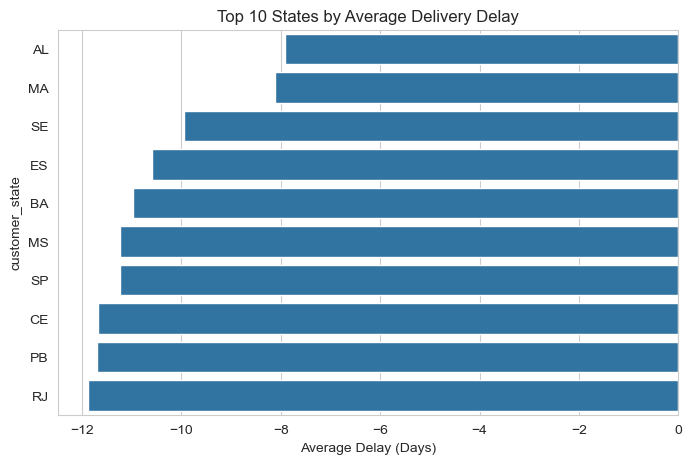

In [8]:
state_delay = (
    df.groupby("customer_state")["delivery_delay_days"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8,5))
sns.barplot(x=state_delay.values, y=state_delay.index)
plt.title("Top 10 States by Average Delivery Delay")
plt.xlabel("Average Delay (Days)")
plt.savefig("Statewise_delivery_delay")
plt.show()

## Statewise Delivery Delay Analysis

We calculated the average delivery delay for each customer state.
Observations:
- The chart shows the top 10 states with the highest average delivery delay.
- States with values closer to zero or positive indicate slower deliveries.
- States with strongly negative values receive orders much earlier than estimated.
Business Insight:
Regional delivery performance varies significantly. 
States with higher average delays may require logistics optimization, better courier allocation or more accurate delivery estimates.

In [9]:
corr = df[["payment_value","payment_installments"]].corr().iloc[0,1]
print("Correlation:", round(corr,3))

Correlation: 0.295


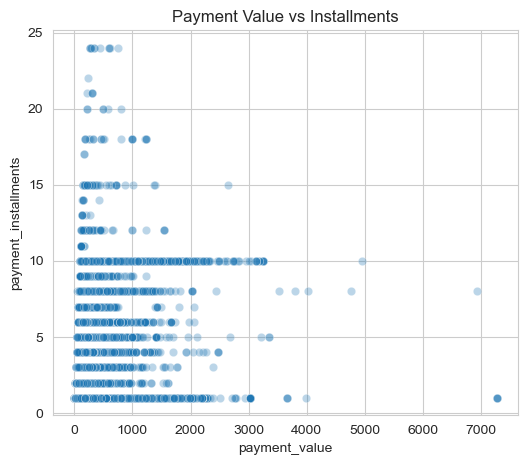

In [10]:
plt.figure(figsize=(6,5))
sns.scatterplot(
    data=df,
    x="payment_value",
    y="payment_installments",
    alpha=0.3
)
plt.title("Payment Value vs Installments")
plt.savefig("Payment_value_vs_Installments")
plt.show()

In [11]:
X = df[["payment_value"]]
y = df["payment_installments"]

model = LinearRegression()
model.fit(X, y)

print("R2 Score:", r2_score(y, model.predict(X)))

R2 Score: 0.08676349765808233


## Relationship Between Payment Value and Installments

The correlation coefficient between payment value and installments is **0.295**, indicating a weak positive relationship. This means that while higher payment values tend to have slightly more installments, the relationship is not strong.

The scatter plot shows:
- Most payments are below 2000.
- Installments are typically between 1 and 10.
- No clear linear upward pattern.
- Several high-value payments are made in a single installment.
This suggests that installment choice depends more on customer preference or payment policy rather than strictly on transaction amount.

The R² score of the linear regression model is **0.087**.
This means that only about **8.7% of the variation in payment installments** can be explained by payment value alone.

Although there is a slight positive relationship, payment value is not a strong predictor of the number of installments. Other factors such as customer behavior, credit policy or promotional offers likely influence installment selection.


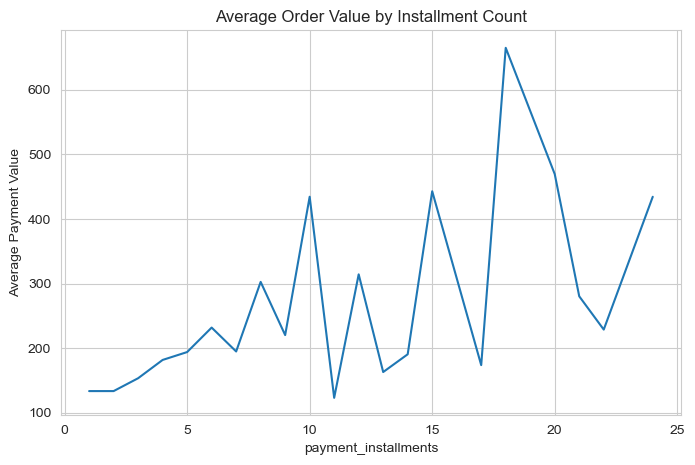

In [26]:
installment_analysis = (
    df.groupby("payment_installments")["payment_value"]
    .mean()
)

plt.figure(figsize=(8,5))
installment_analysis.plot()
plt.title("Average Order Value by Installment Count")
plt.ylabel("Average Payment Value")
plt.savefig("Average_order_value_by_Installment_count")
plt.show()

## Average Order Value by Installment Count

To better understand the relationship between payment amount and installment behavior, we grouped the data by `payment_installments` and calculated the average `payment_value` for each installment count.

- In general the average payment value tends to increase as the number of installments increases.
- Customers choosing higher installment counts often correspond to higher average order values.
- However, the trend is not perfectly smooth and shows fluctuations at certain installment counts.
- Very high installment numbers (e.g., above 15) show sharp spikes, which may be due to fewer transactions in those categories.

This analysis suggests that customers typically use more installments for higher-value purchases. However, the variability at higher installment counts indicates that installment usage is influenced not only by order value but also by customer preference, credit availability, or promotional financing options.

While payment value has a moderate influence on installment count, it is not the sole determining factor. Installment behavior appears to be partially value-driven but also shaped by external payment policies and customer decisions.

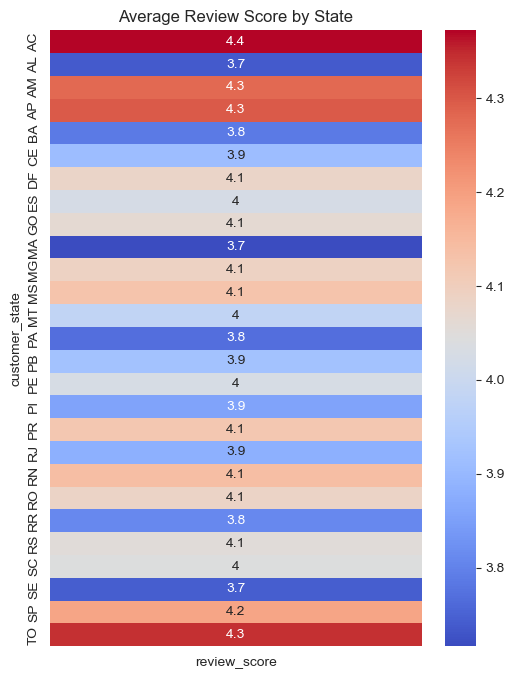

In [25]:
state_review = (
    df.groupby("customer_state")["review_score"]
    .mean()
    .reset_index()
)

pivot = state_review.pivot_table(
    values="review_score",
    index="customer_state"
)

plt.figure(figsize=(6,8))
sns.heatmap(pivot, annot=True, cmap="coolwarm")
plt.title("Average Review Score by State")
plt.savefig("Average_review_score_by_State")
plt.show()

## Average Review Score by State

Calculated the average `review_score` for each `customer_state` and visualized it using a heatmap
- Most states have average review scores between 3.7 and 4.4.
- The variation across states is relatively small.
- Some states show slightly higher customer satisfaction compared to others.

Customer satisfaction is generally consistent across states, with only minor regional differences in average review scores.

In [17]:
df[["delivery_delay_days", "review_score"]].corr()

,delivery_delay_days,review_score
delivery_delay_days,1.000000,-0.235034
review_score,-0.235034,1.000000


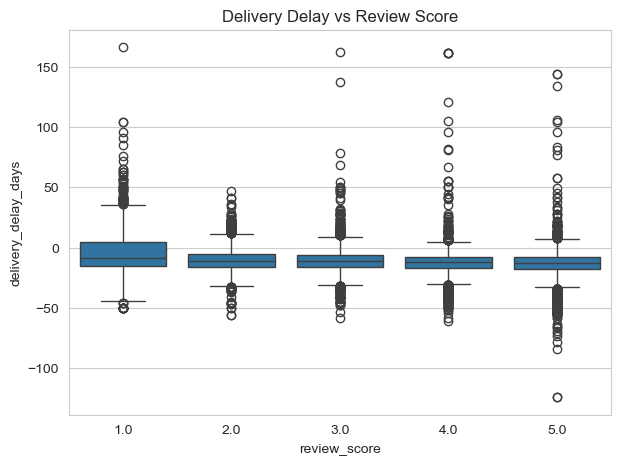

In [24]:
plt.figure(figsize=(7,5))
sns.boxplot(
    data=df,
    x="review_score",
    y="delivery_delay_days"
)
plt.title("Delivery Delay vs Review Score")
plt.savefig("Delivery_delay_vs_Review_score")
plt.show()

In [20]:
data = df[["delivery_delay_days", "review_score"]].dropna()

X = data[["delivery_delay_days"]]
y = data["review_score"]

model = LinearRegression()
model.fit(X, y)

print("R2:", r2_score(y, model.predict(X)))

R2: 0.0552411598806527


## Delivery Delay vs Review Score

The correlation between delivery delay and review score is **-0.235**, indicating a weak negative relationship.
This suggests that as delivery delay increases (late deliveries), review scores tend to decrease slightly.
The linear regression model gives an R² of **0.055**, meaning delivery delay explains only about 5.5% of the variation in review scores.

Delivery delay has some impact on customer ratings, but it is not a strong predictor on its own.

In [33]:
df["review_response_days"] = (
    df["review_answer_timestamp"] -
    df["review_creation_date"]
).dt.days

clean_data = df["review_response_days"].dropna()
clean_data = clean_data[clean_data >= 0]

print("Mean:", df["review_response_days"].mean())
print("Median:", df["review_response_days"].median())
print("95th percentile:", df["review_response_days"].quantile(0.95))
print("Max:", clean_data.max())

Mean: 2.588642770841724
Median: 1.0
95th percentile: 6.0
Max: 518.0


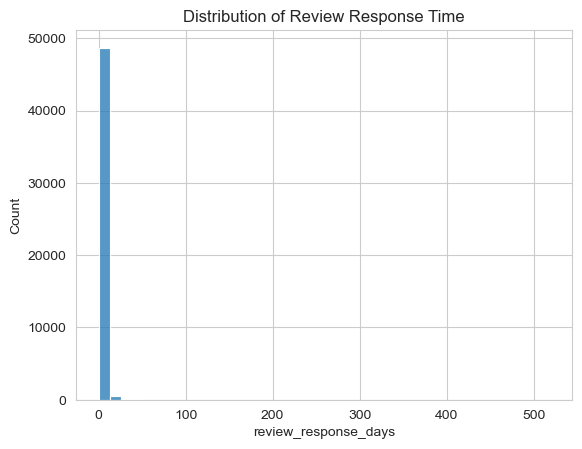

In [34]:
upper_limit = clean_data.quantile(0.95)
filtered_data = clean_data[clean_data <= upper_limit]

sns.histplot(df["review_response_days"], bins=40)
plt.title("Distribution of Review Response Time")
plt.savefig("Distribution_of_Review_Response_Time")
plt.show()

## Review Response Time Analysis

We calculated the number of days taken to respond to customer reviews by subtracting the review creation date from the review answer timestamp.
- Mean response time: **2.59 days**
- Median response time: **1 day**
- 95% of responses are given within **6 days**
- Maximum response time: **518 days**

The data is highly right-skewed due to a few extreme outliers (very delayed responses).  
However, since 95% of responses occur within 6 days and the median is just 1 day, most sellers respond very quickly.

In [29]:
category_review = (
    df.groupby("product_category_name")
    .agg(
        avg_review=("review_score","mean"),
        revenue=("price","sum")
    )
    .sort_values("avg_review")
)

print(category_review)

                                               avg_review    revenue
product_category_name                                               
portateis_cozinha_e_preparadores_de_alimentos    2.333333    1087.90
seguros_e_servicos                               2.500000     283.29
fraldas_higiene                                  3.000000     936.90
pc_gamer                                         3.333333     389.97
moveis_escritorio                                3.570674  123030.40
...                                                   ...        ...
livros_tecnicos                                  4.547170    7076.42
dvds_blu_ray                                     4.551724    3169.95
livros_interesse_geral                           4.581818   17919.14
cds_dvds_musicais                                4.857143     375.00
fashion_roupa_infanto_juvenil                    5.000000     129.98

[73 rows x 2 columns]


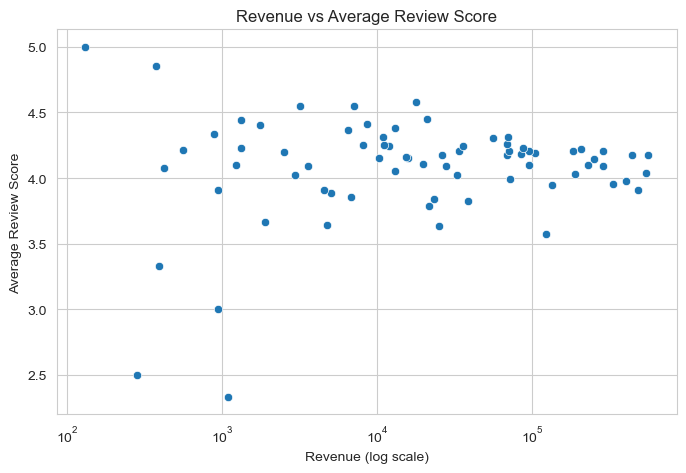

In [35]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=category_review.reset_index(),
    x="revenue",
    y="avg_review"
)
plt.xscale("log")
plt.title("Revenue vs Average Review Score")
plt.xlabel("Revenue (log scale)")
plt.ylabel("Average Review Score")
plt.savefig("Revenue_vs_Average_review_score")
plt.show()

## Revenue vs Average Review Score (Log Scale)

We analyzed the relationship between total category revenue and average review score.  
Since revenue is highly skewed, a logarithmic scale was applied for better visualization.
- Most categories have average ratings between **3.8 and 4.3**.
- There is no clear upward or downward trend between revenue and rating.
- Some low-revenue categories have very high ratings, while some high-revenue categories have moderate ratings.

Category-level revenue does not strongly depend on average review score.  
Customer ratings and revenue appear to be relatively independent at the aggregated category level.

In [36]:
df["actual_delivery_days"] = (
    df["order_delivered_customer_date"] -
    df["order_purchase_timestamp"]
).dt.days

df[["product_weight_g", "actual_delivery_days"]].corr()

,product_weight_g,actual_delivery_days
product_weight_g,1.000000,0.092341
actual_delivery_days,0.092341,1.000000


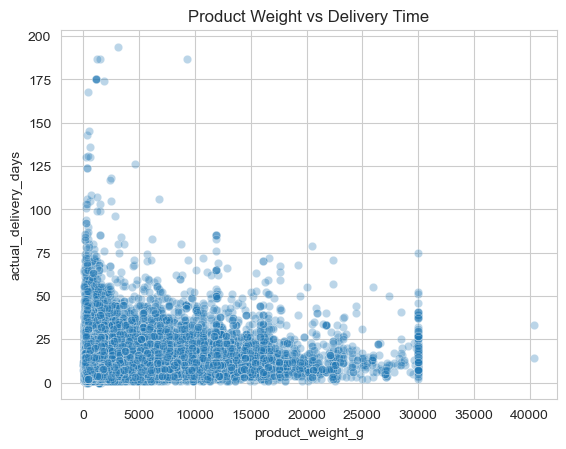

In [38]:
sns.scatterplot(
    data=df,
    x="product_weight_g",
    y="actual_delivery_days",
    alpha=0.3
)
plt.title("Product Weight vs Delivery Time")
plt.savefig("Product_weight_vs_Delivery_time")
plt.show()

In [40]:
data = df[["product_weight_g", "actual_delivery_days"]].dropna()

X = data[["product_weight_g"]]
y = data["actual_delivery_days"]

model = LinearRegression()
model.fit(X, y)

print("R2:", r2_score(y, model.predict(X)))

R2: 0.008526795799126186


## Product Weight vs Delivery Time Analysis

We analyzed the relationship between product weight (g) and actual delivery days.

- Correlation: **0.09** (very weak positive relationship)
- R² Score: **0.0085**

The scatter plot shows no clear pattern between weight and delivery time.  
The extremely low R² value indicates that **product weight does not significantly impact delivery time**.
Overall delivery duration is likely influenced more by logistics factors (distance, carrier, location) rather than product weight.